In [ ]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg

Standardisation of statistical reporting 

In [ ]:
def interpret(result,null,alt):
    if 'p_val' in result.columns:
        p=result['p_val'].iloc[0]
    elif 'pval' in result.columns:
        p=result['pval'].iloc[0]
    elif 'p_unc' in result.columns:
        p=result['p_unc'].iloc[0]
    print(f"The p value is {p}") 
    if p<=0.05:
        print(f"Reject the null hypothesis and accept the alternate hypothesis(before p value correction).{alt}")
    else:
        print(f"Fail to reject the null hypothesis(before p value correction).{null}")

In [ ]:
def d_interpret(result):
    d=result['cohen_d'].iloc[0]
    print(f"Cohen d is {d}")
    if d<0.2:
        print("Effect size is negligible")
    elif d>=0.2 and d<0.5:
        print("Effect size is small")
    elif d>=0.5 and d<0.8:
        print("Effect size is medium")
    else:
        print("Effect size is large")

In [ ]:
#interpretation
def post_hoc_interpret(df,pheader):
    for index,row in df.iterrows():
        if row[pheader]<=0.05:
            print(f"The difference in mean of cp type {row['A']} and cp type {row['B']}, {abs(row['mean_A']-row['mean_B'])}, is statistically significant.(p={row[pheader]})")
        else:
            print(f"The difference in mean of cp type {row['A']} and cp type {row['B']} is not statistically significant")

In [ ]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
X = heart_disease.data.features
y = heart_disease.data.targets

# combine into one dataframe, like your heart.csv
heart_df = pd.concat([X, y], axis=1)

Basic descriptive stats

In [ ]:
heart_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


NaN values are contained within the data. Drop NaN values

In [ ]:
heart_df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

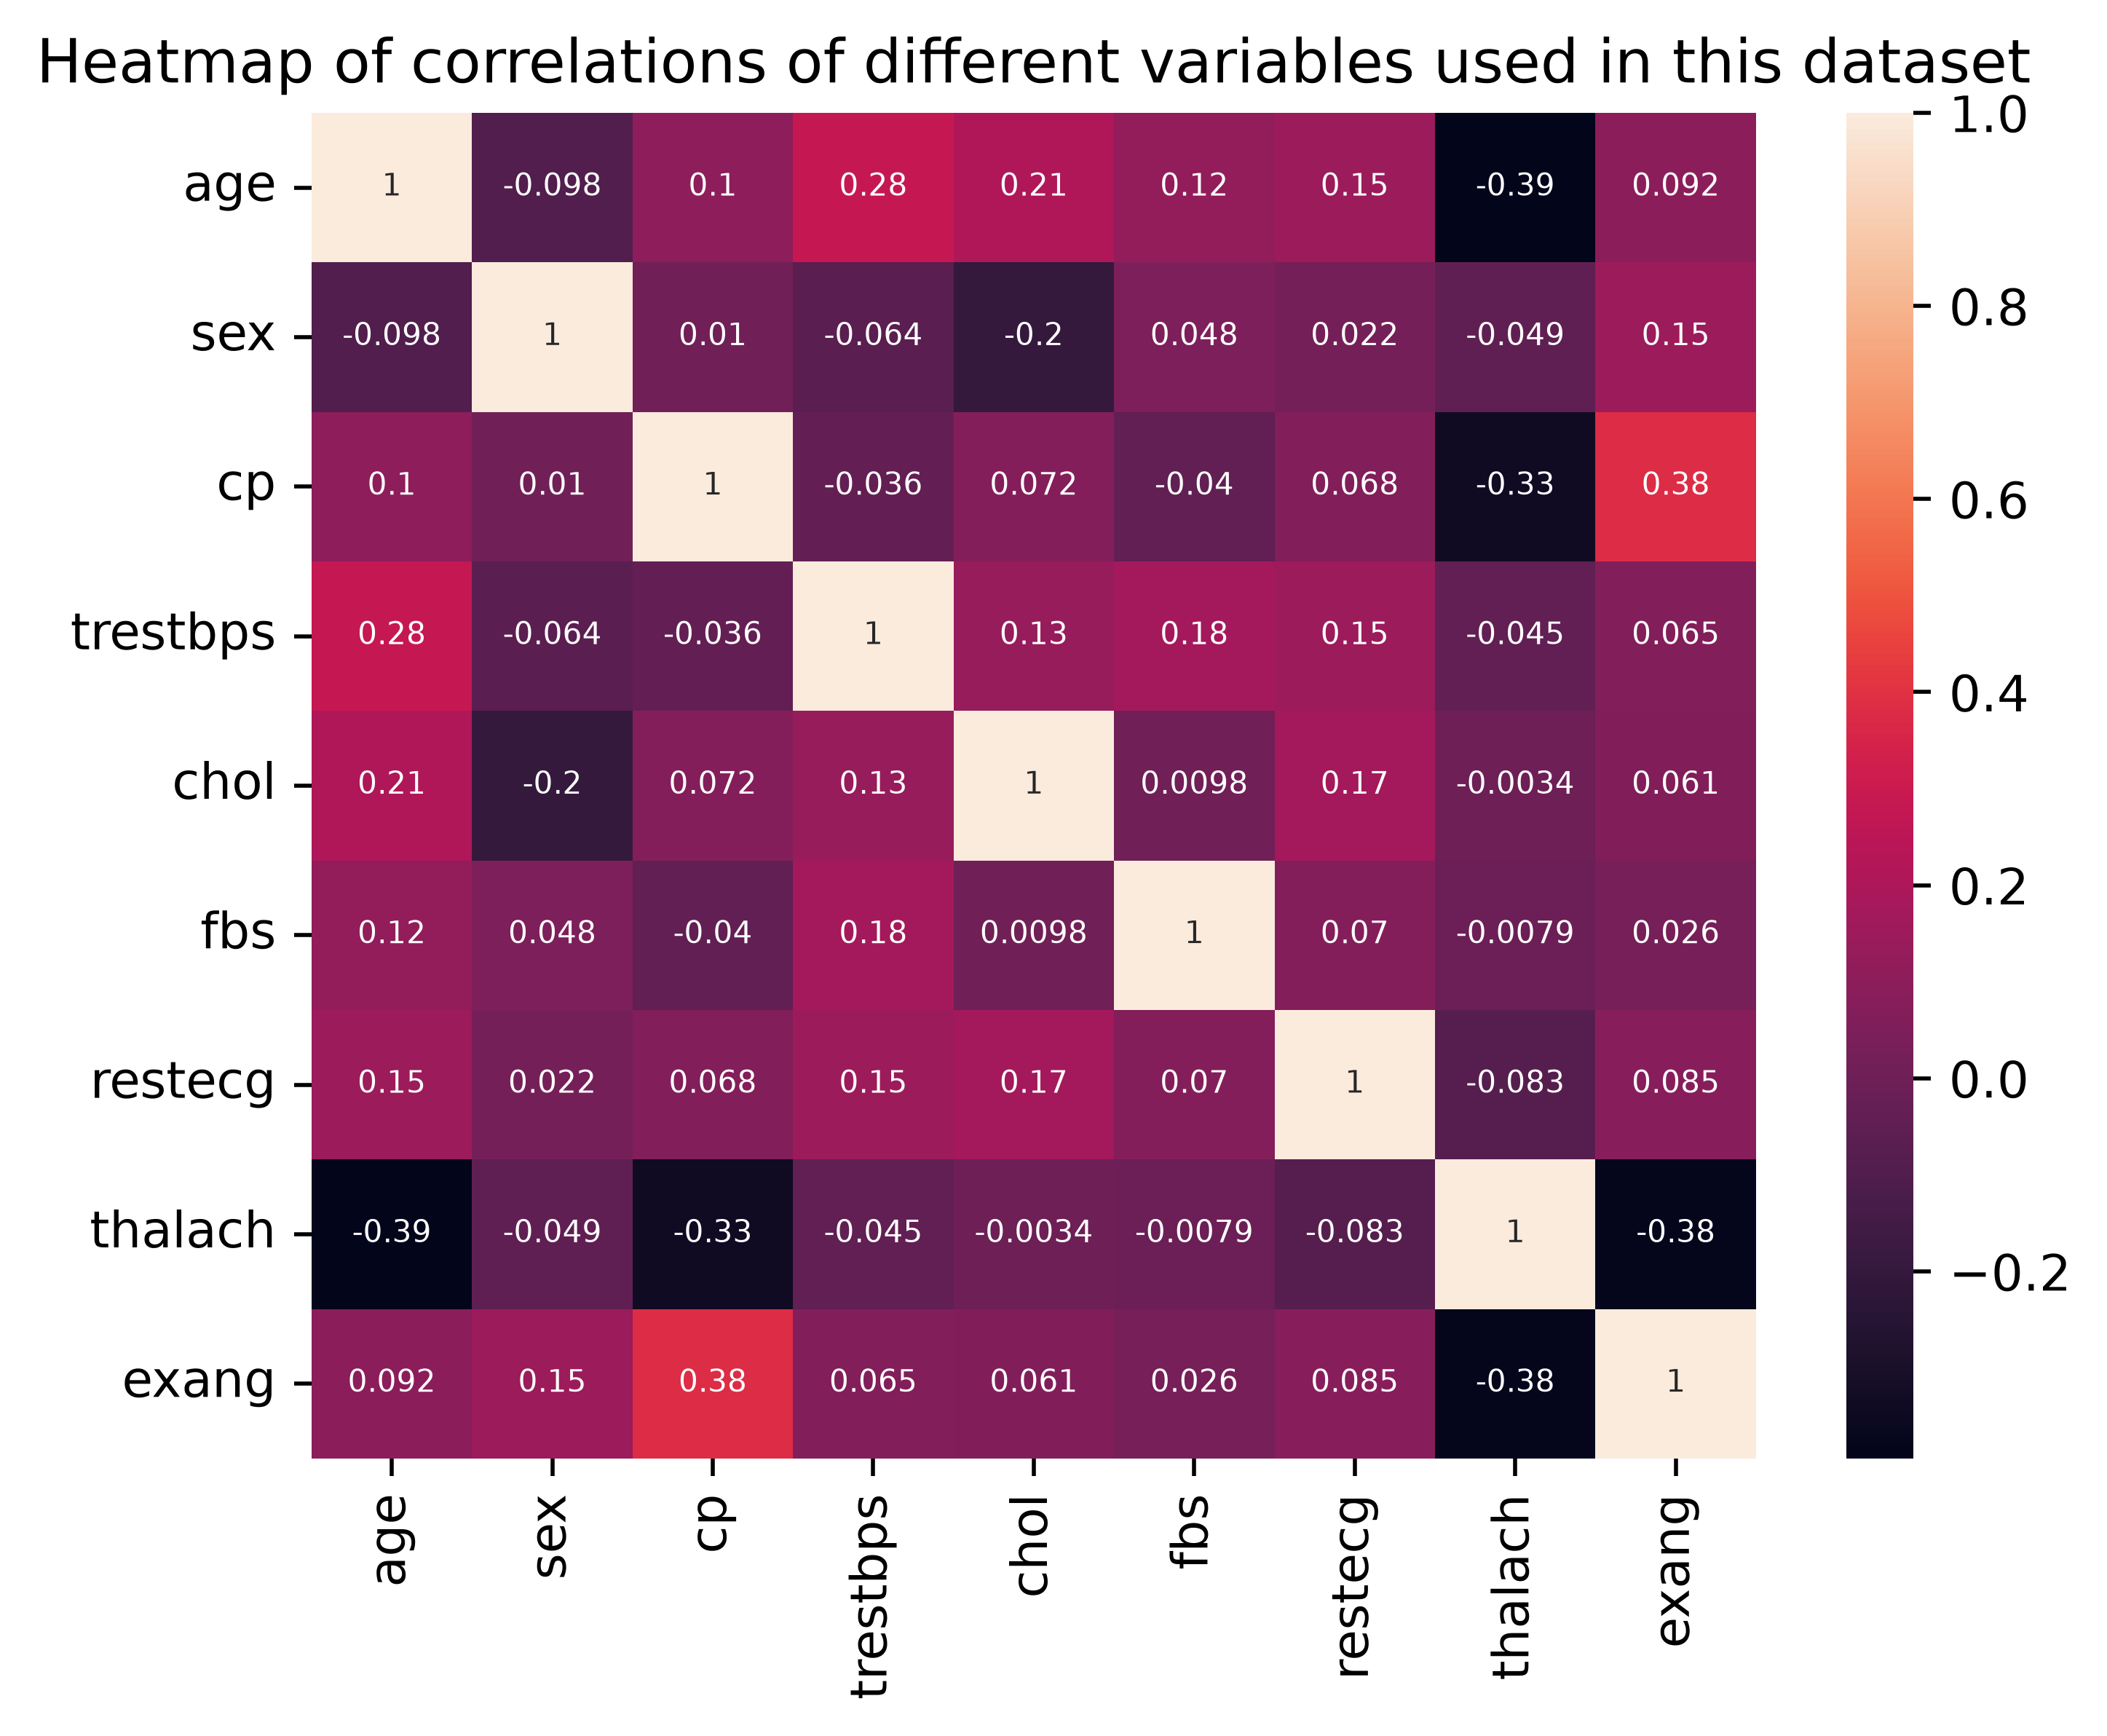

In [ ]:
plt.figure(dpi=500)
#high dpi was needed due to small numbers
sns.heatmap(heart_df[['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang']].corr(),annot=True,annot_kws={"size": 6},)
plt.title('Heatmap of correlations of different variables used in this dataset')
plt.show()

In [ ]:
heart_df=heart_df.dropna()

Verify no NaN values are left

In [ ]:
heart_df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

In [ ]:
heart_df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000
mean,54.542088,0.676768,3.158249,131.693603,247.350168,0.144781,0.996633,149.599327,0.326599,1.055556,1.602694,0.676768,4.730640,0.946128
std,9.049736,0.468500,0.964859,17.762806,51.997583,0.352474,0.994914,22.941562,0.469761,1.166123,0.618187,0.938965,1.938629,1.234551
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,243.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,276.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [ ]:
gender=heart_df.value_counts('sex')
print(f"There are {gender.iloc[0]} male samples and {gender.iloc[1]} female samples")
print(f"There are a total of {gender.iloc[0]+gender.iloc[1]} samples in total")

There are 201 male samples and 96 female samples
There are a total of 297 samples are present


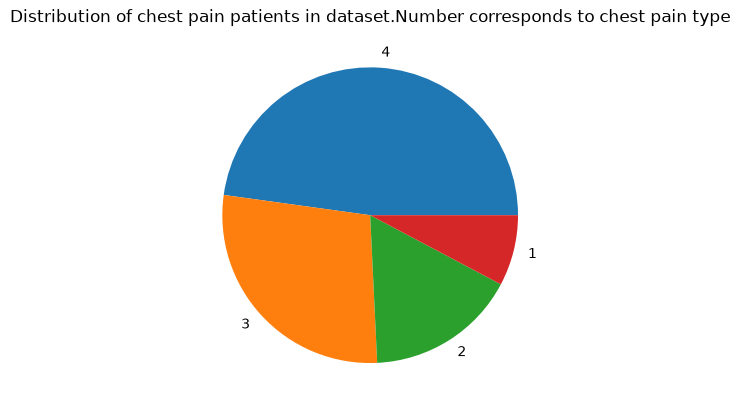

Value 1: typical angina
Value 2: atypical angina
Value 3: non-anginal pain
Value 4: asymptomatic


In [ ]:
pie_series=heart_df['cp'].value_counts(normalize=True)
plt.title("Distribution of chest pain patients in dataset. Number corresponds to chest pain type")
plt.pie(pie_series,labels=pie_series.index)
plt.show()
print("Value 1: typical angina")
print("Value 2: atypical angina")
print('Value 3: non-anginal pain')
print("Value 4: asymptomatic")

In [ ]:
male_df=heart_df.query("sex==1")
female_df=heart_df.query("sex==0")

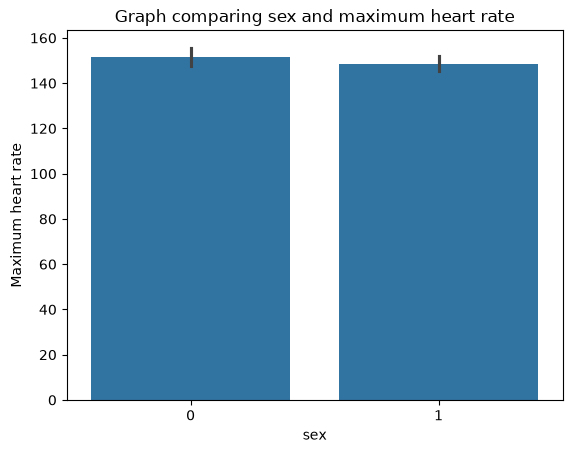

In [ ]:
sns.barplot(y='thalach',x='sex',data=heart_df)
plt.title('Graph comparing sex and maximum heart rate')
plt.ylabel('Maximum heart rate')
plt.show()

In [ ]:
null_hypothesis='There is no statistically significant difference between the mean maximum heart rate of men and women'
alt_hypothesis='The female mean maximum heart rate is statistically greater than the male maximum heart rate'
result=pg.ttest(male_df['thalach'],female_df['thalach'],paired=False,alternative='less')
print(result)
interpret(result,null_hypothesis,alt_hypothesis)

               T         dof alternative     p_val          CI95   cohen_d  \
T_test -1.120169  226.354412        less  0.131915  [-inf, 1.41]  0.129145   

           power  
T_test  0.272164  
The p value is 0.1319145391870775
Fail to reject the null hypothsis.There is no statistically significant difference between the mean maximum heart rate of men and women


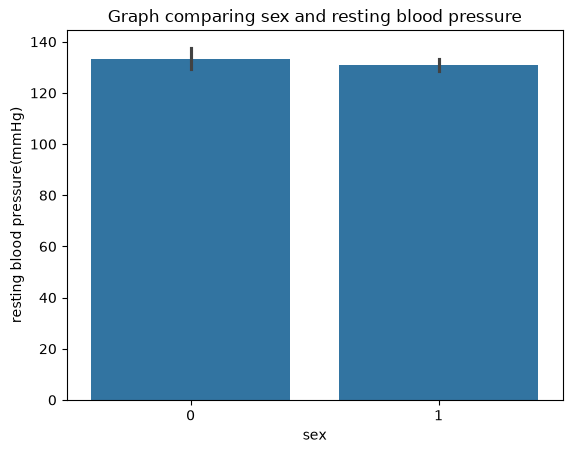

In [ ]:
sns.barplot(y='trestbps',x='sex',data=heart_df)
plt.title('Graph comparing sex and resting blood pressure')
plt.ylabel('resting blood pressure(mmHg)')
plt.show()

In [ ]:
null_hypothesis='There is no statistically significant difference between the mean resting blood pressure of men and women'
alt_hypothesis='The female mean resting blood pressure is statistically greater than the mean male resting blood pressure'
result=pg.ttest(male_df['trestbps'],female_df['trestbps'],paired=False,alternative='less')
print(result)
interpret(result,null_hypothesis,alt_hypothesis)

               T         dof alternative     p_val          CI95   cohen_d  \
T_test -1.085816  165.309536        less  0.139571  [-inf, 1.32]  0.141674   

           power  
T_test  0.306595  
The p value is 0.13957063755899587
Fail to reject the null hypothsis.There is no statistically significant difference between the mean resting blood pressure of men and women


Do men and women have different mean cholestrol levels

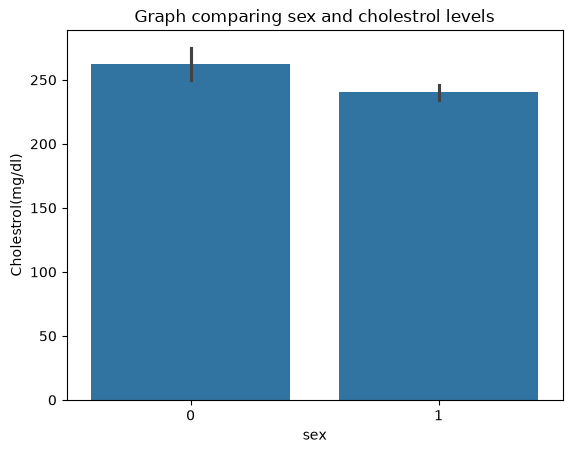

In [ ]:
sns.barplot(y='chol',x='sex',data=heart_df)
plt.title('Graph comparing sex and cholesterol levels')
plt.ylabel('Cholesterol(mg/dl)')
plt.show()

In [ ]:
null_hypothesis='There is no statistically significant difference between the mean cholesterol level of men and women'
alt_hypothesis='The female cholesterol level is statistically greater than the mean cholesterol level of the male cholesterol level'
result=pg.ttest(male_df['chol'],female_df['chol'],paired=False,alternative='less')
print(result)
interpret(result,null_hypothesis,alt_hypothesis)
d_interpret(result)

               T         dof alternative     p_val          CI95   cohen_d  \
T_test -3.013477  135.598642        less  0.001541  [-inf, -9.9]  0.430634   

           power  
T_test  0.965487  
The p value is 0.001541475622369656
Reject the null hypothesis and accept the alternate hypothesis.The female cholestrol level is statistically greater than the mean cholestrol level than the male cholestrol level
Cohen d is 0.43063414879512113
Effect size is small


Do different chest pain types have different resting blood pressures?

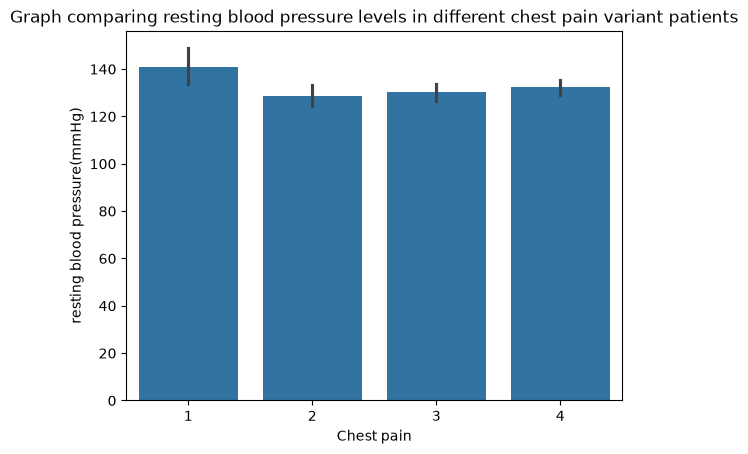

cp
4    142
3     83
2     49
1     23
Name: count, dtype: int64


In [ ]:
sns.barplot(x='cp',y='trestbps',data=heart_df)
plt.title('Graph comparing resting blood pressure levels in different chest pain variant patients')
plt.ylabel('resting blood pressure(mmHg)')
plt.xlabel('Chest pain')
plt.show()
print(heart_df.value_counts('cp'))

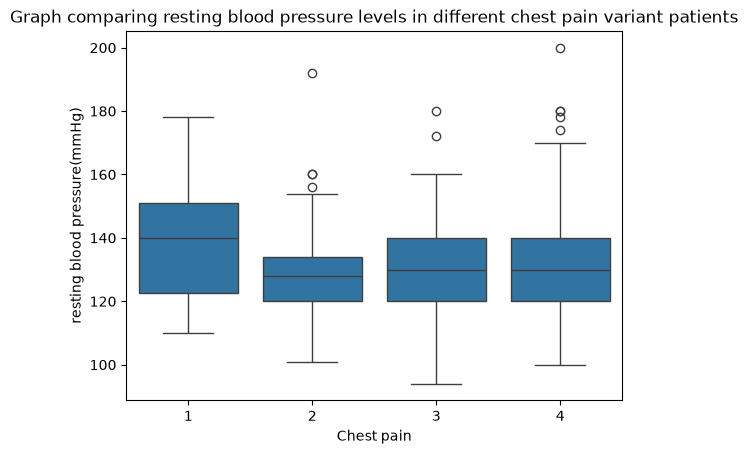

cp
4    142
3     83
2     49
1     23
Name: count, dtype: int64


In [ ]:
sns.boxplot(x='cp',y='trestbps',data=heart_df)
plt.title('Graph comparing resting blood pressure levels in different chest pain variant patients')
plt.ylabel('resting blood pressure(mmHg)')
plt.xlabel('Chest pain')
plt.show()
print(heart_df.value_counts('cp'))

We need to test if cp type=2 has normality to check whether we can use ANOVA or have to use kruskal wallis, since cp type=2 has small sample size and heavy outliers

In [ ]:
null_hypo="cp type 2 is normally distributed"
alt_hypo="cp type 2 is not normally distributed"
result=pg.normality(data=heart_df.query("cp==2")['trestbps'])
interpret(result,null_hypo,alt_hypo)

The p value is 0.0001380382366428936
Reject the null hypothesis and accept the alternate hypothesis.cp type 2 is not normally distributed


In [ ]:
null_hypo="There are no statistically significant differences between the distributions of resting blood pressure of the 4 types of cp patients"
alt_hypo="There is at least 1 statistically significant difference between the distributions of resting blood pressure of the 4 types of cp patients"
result=pg.kruskal(data=heart_df,dv='trestbps',between='cp')
interpret(result,null_hypo,alt_hypo)

The p value is 0.054853384267183156
Fail to reject the null hypothsis.There are no statistically significant differences between the distributions of resting blood pressure of the 4 types of cp patients


Do rest ecg type 0 and type 2 have different resting blood pressure

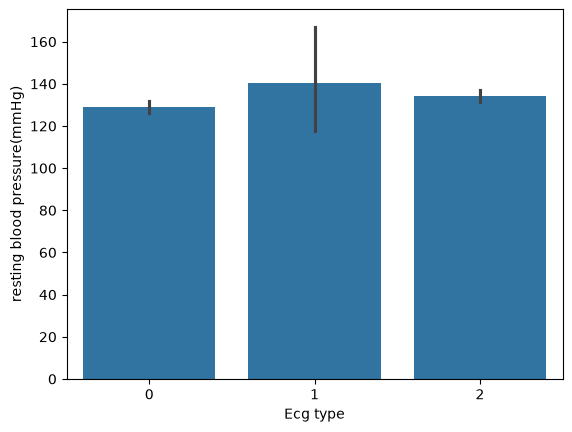

Legend:Type 0=Normal,Type 2=Possible thickening of left ventricle wall


restecg
0    147
2    146
1      4
Name: count, dtype: int64

In [ ]:
sns.barplot(x='restecg',y='trestbps',data=heart_df)
plt.ylabel('resting blood pressure(mmHg)')
plt.xlabel('Ecg type')
plt.show()
print('Legend:Type 0=Normal,Type 2=Possible thickening of left ventricle wall')
heart_df.value_counts('restecg')

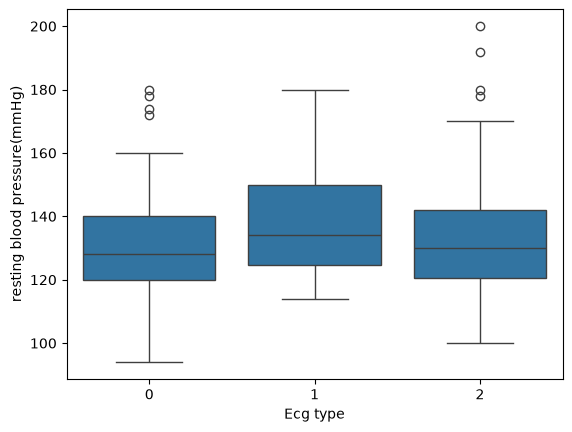

Legend:Type 0=Normal,Type 2=Possible thickening of left ventricle wall


restecg
0    147
2    146
1      4
Name: count, dtype: int64

In [ ]:
sns.boxplot(x='restecg',y='trestbps',data=heart_df)
plt.ylabel('resting blood pressure(mmHg)')
plt.xlabel('Ecg type')
plt.show()
print('Legend:Type 0=Normal,Type 2=Possible thickening of left ventricle wall')
heart_df.value_counts('restecg')

From boxplot restecg type 2, there are multiple outliers and the data is skewed towards the left. test normality to make sure t-test can be used 

In [ ]:
result=pg.normality(heart_df.query("restecg == 2")['trestbps'])
print(result)

                 W      pval  normal
trestbps  0.961955  0.000458   False


Unable to use t test, use Mann Whitney U test instead.Ignore type 1 rest ecg, sample size too small

In [ ]:
null_hypo='The difference in distribution of resting blood pressure of type 0 and 2 restecg is not statistically significant'
alt_hypo='Type 2 ecg tends to have higher resting blood pressure than type 1 ecg'
result=pg.mwu(heart_df.query('restecg == 0')['trestbps'],heart_df.query('restecg == 2')['trestbps'],alternative='less')
print(result)
interpret(result,null_hypo,alt_hypo)

      U_val alternative     p_val       RBC      CLES
MWU  8914.0        less  0.005997 -0.169323  0.584661
The p value is 0.00599683341754541
Reject the null hypothesis and accept the alternate hypothesis.Type 2 ecg tends to have higher resting blood pressure than type 1 ecg


Difference between resting blood pressure of type 0 and type 2 ecg is small (-0.169323)

Difference in cholestrol levels of restecg group 0 and 2(male)

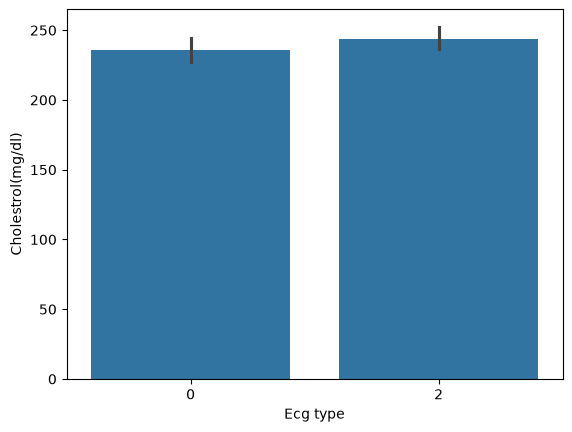

Legend:Type 0=Normal,Type 2=Possible thickening of left ventricle wall


restecg
2    102
0     98
1      1
Name: count, dtype: int64

In [ ]:
sns.barplot(x='restecg',y='chol',data=male_df.query('restecg != 1'))
plt.ylabel('Cholestrol(mg/dl)')
plt.xlabel('Ecg type')
plt.show()
print('Legend:Type 0=Normal,Type 2=Possible thickening of left ventricle wall')
male_df.value_counts('restecg')

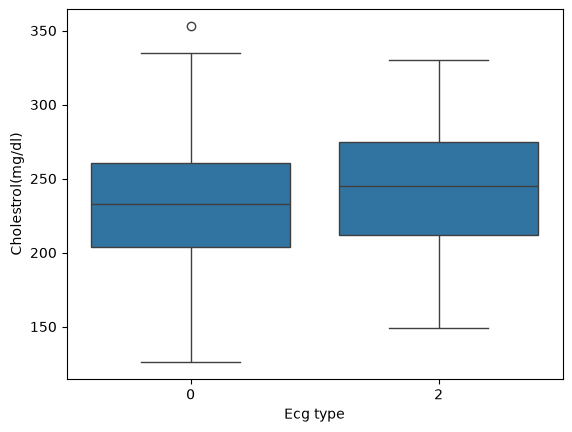

Legend:Type 0=Normal,Type 2=Possible thickening of left ventricle wall


restecg
2    102
0     98
1      1
Name: count, dtype: int64

In [ ]:
sns.boxplot(x='restecg',y='chol',data=male_df.query('restecg != 1'))
plt.xlabel('Ecg type')
plt.ylabel('Cholestrol(mg/dl)')
plt.show()
print('Legend:Type 0=Normal,Type 2=Possible thickening of left ventricle wall')
male_df.value_counts('restecg')

In [ ]:
null_hypo='The difference in mean chol of type 0 and 2 restecg in men is not statistically significant'
alt_hypo='Type 2 restecg tends to have higher mean cholestrol levels than type 0 restecg in men '
result=pg.ttest(male_df.query('restecg == 0')['chol'],male_df.query('restecg == 2')['chol'],alternative='less')
interpret(result,null_hypo,alt_hypo)

The p value is 0.0801852062600235
Fail to reject the null hypothsis.The difference in mean chol of type 0 and 2 restecg in men is not statistically significant


Difference in cholestrol levels of restecg group 0 and 2(female)

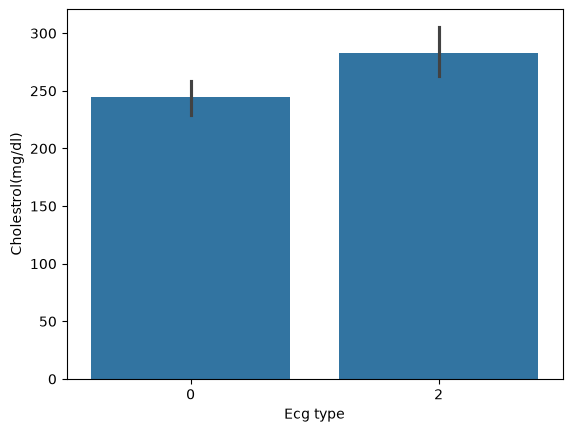

Legend:Type 0=Normal,Type 2=Possible thickening of left ventricle wall


restecg
0    49
2    44
1     3
Name: count, dtype: int64

In [ ]:
sns.barplot(x='restecg',y='chol',data=female_df.query('restecg != 1'))
plt.ylabel('Cholestrol(mg/dl)')
plt.xlabel('Ecg type')
plt.show()
print('Legend:Type 0=Normal,Type 2=Possible thickening of left ventricle wall')
female_df.value_counts('restecg')

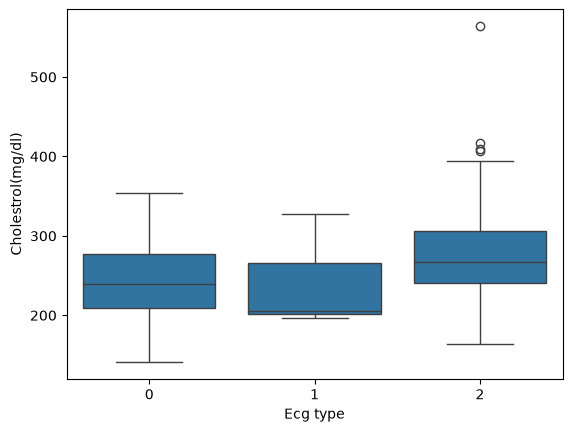

Legend:Type 0=Normal,Type 2=Possible thickening of left ventricle wall


In [ ]:
sns.boxplot(x='restecg',y='chol',data=female_df.query('restecg != 1'))
plt.ylabel('Cholesterol(mg/dl)')
plt.xlabel('Ecg type')
plt.show()
female_df.value_counts('restecg')
print('Legend:Type 0=Normal,Type 2=Possible thickening of left ventricle wall')

In [ ]:
null_hypo='The difference in cholesterol levels of type 0 and 2 restecg is not statistically significant'
alt_hypo='Type 2 restecg tends to have higher cholesterol levels than type 0 restecg'
result=pg.mwu(female_df.query('restecg == 0')['chol'],female_df.query('restecg == 2')['chol'],alternative='less')
interpret(result,null_hypo,alt_hypo)

The p value is 0.004342867366897166
Reject the null hypothesis and accept the alternate hypothesis.Type 2 restecg tends to have higher mean cholestrol levels than type 0 restecg


Interpretation:Difference between cholestrol levels of type 0 and type 2 ecg is small (-0.189964)

Associations

In [ ]:
#calculate strength of relationship between max heart rate and age
null_hypo='The relationship between maximum heart rate and age is not statistically significant'
alt_hypo='The relationship between maximum heart rate and age is statistically significant'
R_df=pg.linear_regression(heart_df['age'],heart_df['thalach'])
#remove first row containing intercept
R_df=R_df.iloc[1:]
print(R_df)
interpret(R_df,null_hypo,alt_hypo)

  names      coef        se         T          pval       r2    adj_r2  \
1   age -1.000238  0.135622 -7.375198  1.670125e-12  0.15568  0.152818   

      CI2.5    CI97.5  
1 -1.267147 -0.733329  
The p value is 1.6701248094406754e-12
Reject the null hypothesis and accept the alternate hypothesis.The relationship between maximum heart rate and age is statistically significant


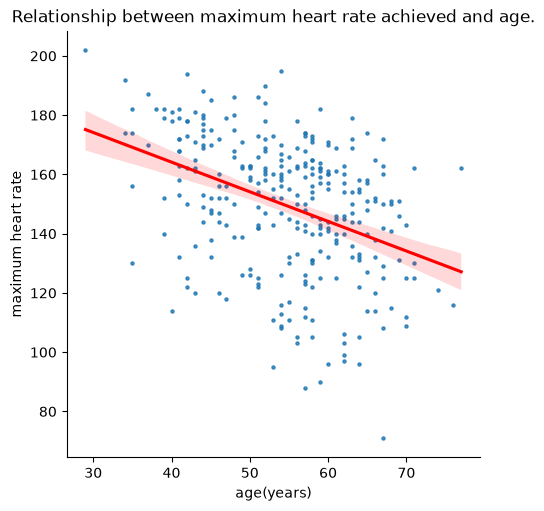

Age explains 15.56798672238402% of the variance in maximum heart rate achieved


In [ ]:
title='Relationship between maximum heart rate achieved and age.'
sns.lmplot(x='age',y='thalach',line_kws={"color": "red"},scatter_kws={"s": 5},data=heart_df)
plt.ylabel('maximum heart rate')
plt.xlabel('age(years)')
plt.title(title)
plt.show()
print(f"Age explains {R_df['r2'].iloc[0]*100}% of the variance in maximum heart rate achieved")

**FINAL RESULT**(p value correction with FDR)

In [ ]:
p = pd.Series({
    ' ttest: max HR, F > M':       0.1319145391870775,
    ' ttest: resting BP, F > M':   0.13957063755899587,
    ' ttest: chol, F>M': 0.001541475622369656,
    'Kruskal: resting BP by cp':    0.054853384267183156,
    'MWU: resting BP, ECG 0 < 2':   0.00599683341754541,
    'ttest: cholesterol, ECG 0 < 2(male)':  0.0801852062600235,
    'MWU: cholesterol, ECG 0 < 2(female)': 0.004342867366897166,
    'Regression: max HR ~ age':     1.6701248094406754e-12,
})

fdr = pd.DataFrame({'p_raw': p})
fdr['sig_fdr'], fdr['p_fdr'] = pg.multicomp(p.values, method='fdr_bh')
print(fdr)

                                            p_raw  sig_fdr         p_fdr
 ttest: max HR, F > M                1.319145e-01    False  1.395706e-01
 ttest: resting BP, F > M            1.395706e-01    False  1.395706e-01
 ttest: chol, F>M                    1.541476e-03     True  6.165902e-03
Kruskal: resting BP by cp            5.485338e-02    False  8.776541e-02
MWU: resting BP, ECG 0 < 2           5.996833e-03     True  1.199367e-02
ttest: cholesterol, ECG 0 < 2(male)  8.018521e-02    False  1.069136e-01
MWU: cholesterol, ECG 0 < 2(female)  4.342867e-03     True  1.158098e-02
Regression: max HR ~ age             1.670125e-12     True  1.336100e-11
